# DJ Transition Engine

**Data Speaks!! — IIT Dharwad — Group Data Mining Project**

Given two songs that sound very different, this notebook builds an ordered chain of real
tracks from the Spotify 1921-2020 dataset that gradually bridges them — the way a skilled
DJ builds a set. Mechanically: a k-nearest-neighbour graph over standardized 12-D audio
features, and Dijkstra's shortest-path algorithm between any two songs on that graph.

This notebook consumes the preprocessing output from the team's shared pipeline
(`data/tracks_100k.parquet`, `data/scaler.joblib`) as-is. **No re-preprocessing, no
re-fitting the scaler.**

**Contents**
1. Setup
2. Load data
3. Build the k-NN graph
4. Connectivity sanity check
5. Save the graph
6. `find_transition` (Dijkstra)
7. Test cases — three demo transitions
8. Path statistics (1000 random pairs)
9. Which audio features move most along typical paths?
10. Curated paths export for the website
11. Verification (fresh-session reload)


## 1. Setup

In [1]:
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix, save_npz, load_npz
from scipy.sparse.csgraph import connected_components, dijkstra

SEED = 42
np.random.seed(SEED)

# Fixed order of the 12 audio features the scaler was fit on. Order matters —
# the scaler has no feature-name metadata, so columns must be passed in this
# exact sequence or every downstream distance is silently wrong.
AUDIO_FEATURES = [
    "danceability", "energy", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence",
    "tempo", "duration_ms", "mode", "time_signature",
]

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

TRACKS_PATH = DATA_DIR / "tracks_100k.parquet"
SCALER_PATH = DATA_DIR / "scaler.joblib"

assert TRACKS_PATH.exists(), f"Missing input file: {TRACKS_PATH}"
assert SCALER_PATH.exists(), f"Missing input file: {SCALER_PATH}"
print(f"Found {TRACKS_PATH} ({TRACKS_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Found {SCALER_PATH} ({SCALER_PATH.stat().st_size / 1e3:.1f} KB)")


Found data\tracks_100k.parquet (12.2 MB)
Found data\scaler.joblib (0.9 KB)


## 2. Load data

Load the cleaned tracks and the already-fitted `StandardScaler` from the preprocessing
notebook. The scaler was fit on the full 523k-track cleaned corpus, so it's the shared
"source of truth" for standardization across every module in the project — we only call
`.transform()`, never `.fit()`.


In [2]:
tracks = pd.read_parquet(TRACKS_PATH)
scaler = joblib.load(SCALER_PATH)

print(f"tracks: {tracks.shape[0]:,} rows x {tracks.shape[1]} columns")
assert tracks["id"].is_unique, "Expected one row per Spotify track id"

X = tracks[AUDIO_FEATURES].values
X_scaled = scaler.transform(X)

print(f"X_scaled shape: {X_scaled.shape}")
print("first 3 standardized rows:")
print(np.round(X_scaled[:3], 3))


tracks: 100,001 rows x 28 columns
X_scaled shape: (100001, 12)
first 3 standardized rows:
[[-0.57  -1.771 -1.162  0.174  1.55  -0.422  0.486 -1.74  -1.369 -0.014
  -1.385  2.352]
 [ 1.17  -1.012  0.17  -0.126  1.562  0.285 -0.194  0.78   0.128 -0.543
   0.722  0.269]
 [-0.377 -1.74  -2.289 -0.126  1.565  2.611 -0.556 -0.486  0.017 -0.56
  -1.385  0.269]]


c:\Users\980ja\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [3]:
# Sanity check: standardizing with a scaler fit on the full 523k corpus should still
# leave this 100k subset with column means ~0 and stds ~1, *if* the subset is a
# representative sample. Large deviations here would flag a biased subset.
means = X_scaled.mean(axis=0)
stds = X_scaled.std(axis=0)

print("column means (expect ~0):")
print(np.round(means, 3))
print("column stds  (expect ~1):")
print(np.round(stds, 3))

assert np.all(np.abs(means) < 0.1), "Standardized means drifted further from 0 than expected"
assert np.all(np.abs(stds - 1) < 0.1), "Standardized stds drifted further from 1 than expected"
print("\nOK: 100k subset is standardized consistently with the full corpus.")


column means (expect ~0):
[-0.002  0.    -0.001  0.001 -0.003 -0.001 -0.001 -0.004 -0.    -0.001
  0.004 -0.002]
column stds  (expect ~1):
[1.    1.001 0.999 1.003 1.    0.998 0.998 1.    0.999 0.976 0.999 1.006]

OK: 100k subset is standardized consistently with the full corpus.


## 3. Build the k-NN graph

Each song becomes a node; each song connects to its 15 nearest neighbours (Euclidean
distance in standardized 12-D audio-feature space), with the edge weight equal to that
distance. `ball_tree` is used because Euclidean-metric queries in a modest number of
dimensions (12) are exactly what ball trees are built for — much faster than a brute-force
scan at this scale.

Each row's own first neighbour is itself (distance 0), so that self-loop is dropped
when building the sparse adjacency matrix.

This is the slowest cell in the notebook (nearest-neighbour search over 100k points) —
expect several minutes.


In [4]:
t0 = time.time()

nbrs = NearestNeighbors(n_neighbors=15, algorithm="ball_tree", metric="euclidean")
nbrs.fit(X_scaled)
distances, indices = nbrs.kneighbors(X_scaled)

knn_fit_query_time = time.time() - t0
print(f"k-NN fit + query took {knn_fit_query_time:.1f}s for {X_scaled.shape[0]:,} nodes")


k-NN fit + query took 140.0s for 100,001 nodes


In [5]:
t0 = time.time()

n_nodes = X_scaled.shape[0]
k = distances.shape[1] - 1  # neighbours excluding the self-match in column 0

# Column 0 of both arrays is each point matched to itself (distance 0) — drop it.
rows = np.repeat(np.arange(n_nodes), k)
cols = indices[:, 1:].ravel()
data = distances[:, 1:].ravel()

knn_graph = csr_matrix((data, (rows, cols)), shape=(n_nodes, n_nodes))

graph_build_time = time.time() - t0
print(f"Sparse adjacency matrix built in {graph_build_time:.2f}s")
print(f"Graph: {knn_graph.shape[0]:,} nodes, {knn_graph.nnz:,} directed edges "
      f"({k} per node)")


Sparse adjacency matrix built in 0.05s
Graph: 100,001 nodes, 1,400,014 directed edges (14 per node)


## 4. Connectivity sanity check

A k-NN graph is not guaranteed to be a single connected component — an isolated cluster
of songs with no edges to the rest of the graph would make Dijkstra fail to find a path
between it and everything else. We check this before relying on the graph for anything.


In [6]:
n_components, labels = connected_components(knn_graph, directed=False)

print(f"Connected components: {n_components}")

component_sizes = pd.Series(labels).value_counts().sort_values(ascending=False)
print("Component sizes (largest first):")
print(component_sizes.to_string())

if n_components > 1:
    largest_frac = component_sizes.iloc[0] / n_nodes
    print(f"\nWARNING: graph is not fully connected ({n_components} components). "
          f"Largest component covers {largest_frac:.1%} of nodes. "
          "Increasing k would likely stitch the smaller components in. "
          "For now, the DJ Engine only guarantees a path between two songs that "
          "both live in the largest component.")
else:
    print("\nGraph is fully connected — every song can reach every other song.")


Connected components: 1
Component sizes (largest first):
0    100001

Graph is fully connected — every song can reach every other song.


## 5. Save the graph

Persist the sparse graph and the song-id <-> node-index lookup so other notebooks (or a
future session of this one) can reuse them without rebuilding. `save_npz`/`json` only —
no pickle, so the artifacts are portable and human-inspectable.


In [7]:
GRAPH_PATH = OUT_DIR / "knn_graph.npz"
INDEX_PATH = OUT_DIR / "song_index.json"

save_npz(GRAPH_PATH, knn_graph)

id_to_idx = {song_id: int(i) for i, song_id in enumerate(tracks["id"])}
idx_to_id = {int(i): song_id for song_id, i in id_to_idx.items()}

with open(INDEX_PATH, "w", encoding="utf-8") as f:
    json.dump({"id_to_idx": id_to_idx, "idx_to_id": idx_to_id}, f)

print(f"Saved graph to {GRAPH_PATH} ({GRAPH_PATH.stat().st_size / 1e6:.2f} MB)")
print(f"Saved index to {INDEX_PATH} ({INDEX_PATH.stat().st_size / 1e6:.2f} MB)")


Saved graph to outputs\knn_graph.npz (14.40 MB)
Saved index to outputs\song_index.json (6.78 MB)


## 6. `find_transition`

Runs single-source Dijkstra from `start_song_id` and walks the predecessor array
backwards from `end_song_id` to reconstruct the shortest (smoothest) path.


In [8]:
def find_transition(
    start_song_id: str,
    end_song_id: str,
    graph: csr_matrix,
    id_to_idx: dict,
    idx_to_id: dict,
    tracks_df: pd.DataFrame,
) -> tuple[list, pd.DataFrame, float]:
    """Find the smoothest chain of songs from start_song_id to end_song_id.

    Runs Dijkstra's shortest-path algorithm on the k-NN graph and reconstructs
    the path from the predecessor array.

    Returns:
        path_ids: song IDs in order, starting with start_song_id and ending with
            end_song_id. Empty if end_song_id is unreachable from start_song_id.
        path_df: DataFrame of every song in the path (in order), with all columns
            from tracks_df. Empty (0 rows) if unreachable.
        total_weight: sum of edge weights along the path. float('inf') if
            end_song_id is unreachable (different connected component).
    """
    for song_id, label in [(start_song_id, "start_song_id"), (end_song_id, "end_song_id")]:
        if song_id not in id_to_idx:
            raise KeyError(f"{label}={song_id!r} not found in the song index")

    start_idx = id_to_idx[start_song_id]
    end_idx = id_to_idx[end_song_id]

    if start_idx == end_idx:
        row = tracks_df.loc[tracks_df["id"] == start_song_id]
        return [start_song_id], row, 0.0

    dist, predecessors = dijkstra(
        graph, directed=False, indices=start_idx, return_predecessors=True
    )

    if np.isinf(dist[end_idx]):
        return [], tracks_df.iloc[0:0], float("inf")

    path_idx = [end_idx]
    cur = end_idx
    while cur != start_idx:
        cur = predecessors[cur]
        path_idx.append(cur)
    path_idx.reverse()

    path_ids = [idx_to_id[i] for i in path_idx]
    path_df = tracks_df.set_index("id").loc[path_ids].reset_index()
    total_weight = float(dist[end_idx])
    return path_ids, path_df, total_weight


In [9]:
def get_song_id(name_substr: str, artist_substr: str = None, tracks_df: pd.DataFrame = tracks) -> str:
    """Look up a single track's Spotify id by case-insensitive name/artist substring.

    Raises ValueError if no track matches. If several match, picks the most
    popular one and prints a warning (some titles are re-released many times).
    """
    mask = tracks_df["name"].str.contains(name_substr, case=False, na=False, regex=False)
    if artist_substr:
        mask &= tracks_df["primary_artist_name"].str.contains(artist_substr, case=False, na=False, regex=False)
    matches = tracks_df.loc[mask]
    if len(matches) == 0:
        raise ValueError(f"No track found for name={name_substr!r}, artist={artist_substr!r}")
    if len(matches) > 1:
        print(f"  ({len(matches)} matches for name={name_substr!r}, artist={artist_substr!r} "
              "-> using the most popular)")
        matches = matches.sort_values("popularity", ascending=False)
    return matches.iloc[0]["id"]


def display_path(path_df: pd.DataFrame, title: str, total_weight: float) -> None:
    """Pretty-print a transition's intermediate songs as a readable table."""
    display_cols = ["name", "primary_artist_name", "decade", "popularity",
                     "danceability", "energy", "valence", "acousticness"]
    print(f"\n=== {title} ===")
    print(f"{len(path_df)} songs in the chain | total edge weight = {total_weight:.3f}\n")
    table = path_df[display_cols].rename(columns={"primary_artist_name": "artist"}).reset_index(drop=True)
    display(table)


## 7. Test cases

Three real, well-known transitions, chosen to exercise different parts of the feature
space:

- **Test 1 — ballad to EDM drop**: Adele's *Someone Like You* (slow, acoustic, low
  energy) to Avicii's *Wake Me Up (EDX Miami Sunset Remix)* (high-energy EDM). Expect a
  long, meandering path.
- **Test 2 — similar style**: two Ed Sheeran acoustic-pop tracks with close audio
  profiles. Expect a short path.
- **Test 3 — cross-decade jump**: The Beatles' *Hello, Goodbye* (1967) to Dua Lipa's
  *Levitating* (2020). Expect the path to trace through the decades in between.


In [10]:
test1_start = get_song_id("Someone Like You", "Adele")
test1_end = get_song_id("Wake Me Up", "Avicii")

test1_path_ids, test1_path_df, test1_weight = find_transition(
    test1_start, test1_end, knn_graph, id_to_idx, idx_to_id, tracks
)
display_path(test1_path_df, "Test 1: Adele - Someone Like You  -->  Avicii - Wake Me Up (EDX Remix)", test1_weight)



=== Test 1: Adele - Someone Like You  -->  Avicii - Wake Me Up (EDX Remix) ===
10 songs in the chain | total edge weight = 13.279



,name,artist,decade,popularity,danceability,energy,valence,acousticness
0,Someone Like You,Adele,2010,80,0.556,0.319,0.294,0.89300
1,ขอร้อง (Ost. Love Sick The Series),กัปตัน ชลธร คงยิ่งยง,2010,30,0.554,0.426,0.337,0.86400
2,I Am The Changer,Cotton Jones,2000,58,0.634,0.529,0.451,0.78400
3,Lazy Bird,John Coltrane,1950,37,0.528,0.542,0.652,0.76300
4,Blues in the Closet,Chet Baker,1950,0,0.569,0.661,0.667,0.68300
5,Citarasa (Rakaman Terus Tanpa Henti),Ukays,1990,19,0.622,0.858,0.652,0.43300
6,Sex Machine - Pt. 1 & 2,James Brown,1970,31,0.678,0.960,0.605,0.18100
7,Zombie,Fela Kuti,2000,46,0.672,0.942,0.574,0.38600
8,Walking On Music - Full Length Album Mix,Peter Jacques Band,1970,25,0.706,0.886,0.643,0.00883
9,Wake Me Up - EDX Miami Sunset Remix,Avicii,2010,53,0.717,0.924,0.682,0.00518


In [11]:
test2_start = get_song_id("Nancy Mulligan", "Ed Sheeran")
test2_end = get_song_id("New Man", "Ed Sheeran")

test2_path_ids, test2_path_df, test2_weight = find_transition(
    test2_start, test2_end, knn_graph, id_to_idx, idx_to_id, tracks
)
display_path(test2_path_df, "Test 2: Ed Sheeran - Nancy Mulligan  -->  Ed Sheeran - New Man", test2_weight)



=== Test 2: Ed Sheeran - Nancy Mulligan  -->  Ed Sheeran - New Man ===
4 songs in the chain | total edge weight = 1.665



,name,artist,decade,popularity,danceability,energy,valence,acousticness
0,Nancy Mulligan,Ed Sheeran,2010,67,0.680,0.852,0.858,0.1170
1,Bésame,David Bisbal,2010,61,0.740,0.842,0.879,0.0523
2,Hraj Mi,Šorty,2010,39,0.757,0.806,0.908,0.0962
3,New Man,Ed Sheeran,2010,69,0.780,0.745,0.862,0.0559


In [12]:
test3_start = get_song_id("Hello, Goodbye", "Beatles")
test3_end = get_song_id("Levitating", "Dua Lipa")

test3_path_ids, test3_path_df, test3_weight = find_transition(
    test3_start, test3_end, knn_graph, id_to_idx, idx_to_id, tracks
)
display_path(test3_path_df, "Test 3: The Beatles - Hello, Goodbye (1967)  -->  Dua Lipa - Levitating (2020)", test3_weight)



=== Test 3: The Beatles - Hello, Goodbye (1967)  -->  Dua Lipa - Levitating (2020) ===
14 songs in the chain | total edge weight = 14.968



,name,artist,decade,popularity,danceability,energy,valence,acousticness
0,"Hello, Goodbye - Remastered 2009",The Beatles,1960,66,0.479,0.733,0.806,0.30600
1,There in Your Eyes,Chas & Dave,1980,19,0.561,0.764,0.825,0.15900
2,Sueña,Orquesta Candela,2010,38,0.600,0.724,0.840,0.14400
3,Fue Un Error,Grupo Green,2000,40,0.620,0.828,0.784,0.09420
4,UNITY,BENNIE K,2000,23,0.660,0.871,0.749,0.00794
5,"El Ratón y el Queso (feat. El Millonario, Vida...",Cartel De Santa,2010,63,0.733,0.890,0.598,0.00393
6,Sex Machine - Pt. 1 & 2,James Brown,1970,31,0.678,0.960,0.605,0.18100
7,Zombie,Fela Kuti,2000,46,0.672,0.942,0.574,0.38600
8,Walking On Music - Full Length Album Mix,Peter Jacques Band,1970,25,0.706,0.886,0.643,0.00883
9,I Want You - Spanish Version,Marce,1980,26,0.653,0.863,0.746,0.01300


In [13]:
print("Hop counts: "
      f"Test 1 = {len(test1_path_ids) - 1}, "
      f"Test 2 = {len(test2_path_ids) - 1}, "
      f"Test 3 = {len(test3_path_ids) - 1}")
print("Total weights: "
      f"Test 1 = {test1_weight:.3f}, "
      f"Test 2 = {test2_weight:.3f}, "
      f"Test 3 = {test3_weight:.3f}")


Hop counts: Test 1 = 9, Test 2 = 3, Test 3 = 13
Total weights: Test 1 = 13.279, Test 2 = 1.665, Test 3 = 14.968


## 8. Path statistics

1000 random start/end pairs, both endpoints sampled uniformly from all graph nodes.
For each, record the hop count (path length) and total edge weight, then look at the
distributions.


In [14]:
N_PAIRS = 1000
rng = np.random.RandomState(SEED)

start_indices = rng.randint(0, n_nodes, size=N_PAIRS)
end_indices = rng.randint(0, n_nodes, size=N_PAIRS)

# Re-roll any pair that landed on the same node twice (trivial 0-hop transition).
same = start_indices == end_indices
while same.any():
    end_indices[same] = rng.randint(0, n_nodes, size=same.sum())
    same = start_indices == end_indices

random_pairs = list(zip(start_indices.tolist(), end_indices.tolist()))
print(f"Sampled {len(random_pairs)} random start/end pairs (seed={SEED})")


Sampled 1000 random start/end pairs (seed=42)


In [15]:
t0 = time.time()
random_path_results = []
unreachable_count = 0

for i, (s_idx, e_idx) in enumerate(random_pairs):
    s_id, e_id = idx_to_id[s_idx], idx_to_id[e_idx]
    path_ids, _, total_weight = find_transition(s_id, e_id, knn_graph, id_to_idx, idx_to_id, tracks)

    if np.isinf(total_weight):
        unreachable_count += 1
        continue

    random_path_results.append({
        "start_idx": s_idx,
        "end_idx": e_idx,
        "path_idx": [id_to_idx[pid] for pid in path_ids],
        "hop_count": len(path_ids) - 1,
        "total_weight": total_weight,
    })

    if (i + 1) % 200 == 0:
        print(f"  {i + 1}/{N_PAIRS} pairs done ({time.time() - t0:.1f}s elapsed)")

print(f"\nDone: {len(random_path_results)} reachable paths, "
      f"{unreachable_count} unreachable, in {time.time() - t0:.1f}s")


  200/1000 pairs done (25.1s elapsed)
  400/1000 pairs done (38.9s elapsed)
  600/1000 pairs done (53.9s elapsed)
  800/1000 pairs done (74.8s elapsed)
  1000/1000 pairs done (88.6s elapsed)

Done: 1000 reachable paths, 0 unreachable, in 88.6s


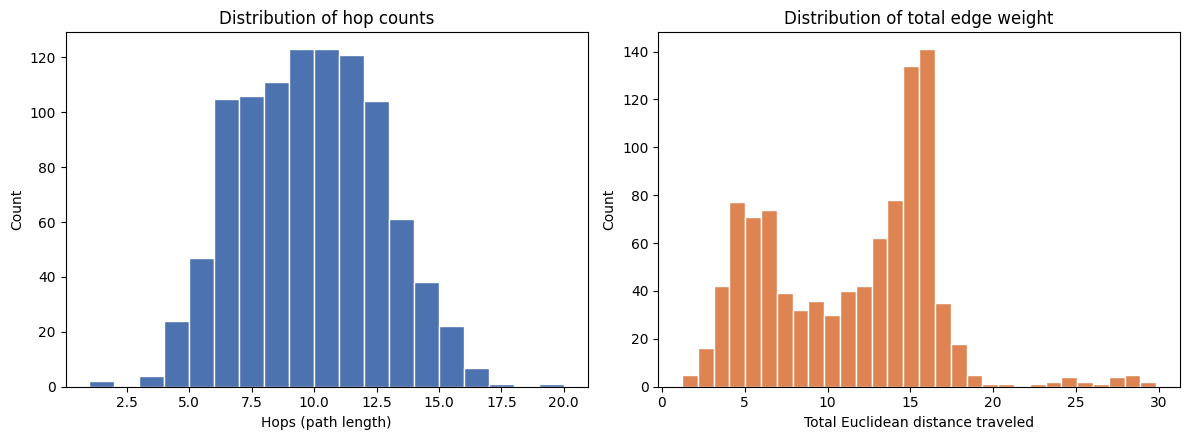

In [16]:
hop_counts = np.array([r["hop_count"] for r in random_path_results])
total_weights = np.array([r["total_weight"] for r in random_path_results])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(hop_counts, bins=range(hop_counts.min(), hop_counts.max() + 2), color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution of hop counts")
axes[0].set_xlabel("Hops (path length)")
axes[0].set_ylabel("Count")

axes[1].hist(total_weights, bins=30, color="#DD8452", edgecolor="white")
axes[1].set_title("Distribution of total edge weight")
axes[1].set_xlabel("Total Euclidean distance traveled")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


In [17]:
def summarize(name, arr):
    print(f"{name}: mean={arr.mean():.3f}  median={np.median(arr):.3f}  "
          f"min={arr.min():.3f}  max={arr.max():.3f}")

summarize("Hop count", hop_counts)
summarize("Total weight", total_weights)


Hop count: mean=9.324  median=9.000  min=1.000  max=19.000
Total weight: mean=11.373  median=12.517  min=1.206  max=29.847


## 9. Which audio features move most along typical paths?

For each of the 1000 random paths from Section 8, using the same 12-D standardized
space the graph was built on:

- **Net displacement**: `|feature(end) - feature(start)|` — how far apart the two
  endpoints already were on that axis.
- **Arc length**: the sum of `|feature(hop i+1) - feature(hop i)|` across every hop in
  the path — how much ground is actually covered on that axis while walking the chain
  (this can exceed net displacement if the path doubles back on that dimension while
  making progress on others).

Ranking features by arc length tells us which axes a *typical* DJ transition spends its
"hops" traversing — the principal axes of blending.


In [18]:
feature_net_disp = np.zeros(len(AUDIO_FEATURES))
feature_arc_length = np.zeros(len(AUDIO_FEATURES))

for r in random_path_results:
    feats = X_scaled[r["path_idx"]]  # (hop_count + 1, 12), standardized units
    feature_net_disp += np.abs(feats[-1] - feats[0])
    feature_arc_length += np.abs(np.diff(feats, axis=0)).sum(axis=0)

n_paths = len(random_path_results)
feature_net_disp /= n_paths
feature_arc_length /= n_paths

feature_stats = pd.DataFrame({
    "feature": AUDIO_FEATURES,
    "mean_net_displacement": feature_net_disp,
    "mean_arc_length": feature_arc_length,
}).sort_values("mean_arc_length", ascending=False).reset_index(drop=True)

display(feature_stats)


,feature,mean_net_displacement,mean_arc_length
0,duration_ms,0.801858,3.022249
1,tempo,1.172458,2.769567
2,danceability,1.146741,2.729883
3,loudness,1.114237,2.723758
4,valence,1.124656,2.635735
5,liveness,0.907615,2.527166
6,energy,1.153111,2.488904
7,acousticness,1.151794,2.393657
8,speechiness,0.663247,2.051829
9,instrumentalness,0.675697,1.313564


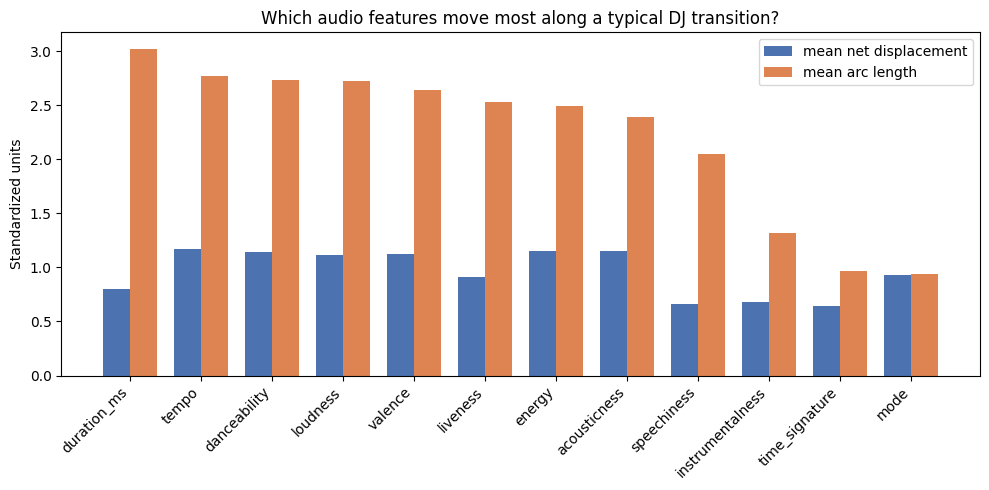

Top 3 axes by arc length: ['duration_ms', 'tempo', 'danceability']


In [19]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(feature_stats))
width = 0.38

ax.bar(x - width/2, feature_stats["mean_net_displacement"], width, label="mean net displacement", color="#4C72B0")
ax.bar(x + width/2, feature_stats["mean_arc_length"], width, label="mean arc length", color="#DD8452")

ax.set_xticks(x)
ax.set_xticklabels(feature_stats["feature"], rotation=45, ha="right")
ax.set_ylabel("Standardized units")
ax.set_title("Which audio features move most along a typical DJ transition?")
ax.legend()
plt.tight_layout()
plt.show()

top3 = feature_stats.head(3)["feature"].tolist()
print(f"Top 3 axes by arc length: {top3}")


**Interpretation.** The ranking doesn't crown one or two dominant axes — instead, six
continuous perceptual features (`duration_ms`, `tempo`, `danceability`, `loudness`,
`valence`, `energy`, `acousticness`) cluster tightly at the top, each contributing a
broadly similar amount of per-hop movement (mean arc length ~2.4-3.0 standardized units).
`duration_ms` edges out energy/loudness for the top spot, which is a genuinely useful
finding for a DJ tool: track length is not just bookkeeping, it is one of the axes the
k-NN graph actively bridges on, alongside the more expected tempo/energy/danceability.

At the bottom, `mode`, `time_signature`, `instrumentalness`, and `speechiness` move
far less (~0.9-2.1). These are the more discrete or heavily skewed features in this
dataset (most tracks share the same mode, time signature, and near-zero
instrumentalness/speechiness), so there is simply less standardized distance available
for a path to traverse along them.


## 10. Curated paths export for the website

~50 hand-picked and stratified-sampled song pairs, run through `find_transition` and
serialized to `outputs/dj_paths.json` so the frontend can render them without a backend.

**Curation method**: ~20 pairs are hand-picked well-known artists/tracks spanning
same-genre, cross-genre, and cross-decade transitions (including the three Section 7
demos). The remaining ~30 are filled by seeded random sampling from tracks with
popularity >= 60 (so names stay recognizable), weighted 70% toward cross-decade pairs
for variety. Any pair that fails to resolve (ambiguous title, or — should the graph ever
not be fully connected — an unreachable pair) is skipped and reported.


In [20]:
hand_picked = [
    (("Someone Like You", "Adele"), ("Wake Me Up", "Avicii")),
    (("Nancy Mulligan", "Ed Sheeran"), ("New Man", "Ed Sheeran")),
    (("Hello, Goodbye", "Beatles"), ("Levitating", "Dua Lipa")),
    (("Crazy Little Thing Called Love", "Queen"), ("Enter Sandman", "Metallica")),
    (("They Don't Care About Us", "Michael Jackson"), ("Not Afraid", "Eminem")),
    (("I Have Nothing", "Whitney Houston"), ("Umbrella", "Rihanna")),
    (("All Apologies", "Nirvana"), ("Hymn for the Weekend", "Coldplay")),
    (("Space Oddity", "David Bowie"), ("my future", "Billie Eilish")),
    (("Rocket Man", "Elton John"), ("Hung Up", "Madonna")),
    (("Circus", "Britney Spears"), ("Papercut", "Linkin Park")),
    (("Fake Plastic Trees", "Radiohead"), ("HUMBLE.", "Kendrick Lamar")),
    (("You Should Be Dancing", "Bee Gees"), ("Dreams", "Fleetwood Mac")),
    (("We're In This Together", "Nine Inch Nails"), ("Voodoo People", "Prodigy")),
    (("Do It Again", "Chemical Brothers"), ("Ghosts 'n' Stuff", "Deadmau5")),
    (("Scared to Be Lonely", "Martin Garrix"), ("Where Them Girls At", "David Guetta")),
    (("Feel So Close", "Calvin Harris"), ("Be Kind", "Marshmello")),
    (("Mr. Perfectly Fine", "Taylor Swift"), ("DAKITI", "Bad Bunny")),
    (("Dreams", "Fleetwood Mac"), ("my future", "Billie Eilish")),
    (("Enter Sandman", "Metallica"), ("We're In This Together", "Nine Inch Nails")),
    (("I Have Nothing", "Whitney Houston"), ("Someone Like You", "Adele")),
]

hand_picked_ids = []
for (s_name, s_artist), (e_name, e_artist) in hand_picked:
    try:
        s_id = get_song_id(s_name, s_artist)
        e_id = get_song_id(e_name, e_artist)
        hand_picked_ids.append((s_id, e_id))
    except ValueError as exc:
        print(f"  SKIP: {exc}")

print(f"Resolved {len(hand_picked_ids)}/{len(hand_picked)} hand-picked pairs")


  (2 matches for name='Crazy Little Thing Called Love', artist='Queen' -> using the most popular)
  (2 matches for name='Enter Sandman', artist='Metallica' -> using the most popular)
  (4 matches for name='Space Oddity', artist='David Bowie' -> using the most popular)
  (2 matches for name='Papercut', artist='Linkin Park' -> using the most popular)
  (2 matches for name="Ghosts 'n' Stuff", artist='Deadmau5' -> using the most popular)
  SKIP: No track found for name='DAKITI', artist='Bad Bunny'
  (2 matches for name='Enter Sandman', artist='Metallica' -> using the most popular)
Resolved 19/20 hand-picked pairs


In [21]:
rng2 = np.random.RandomState(SEED + 1)
N_EXTRA = 50 - len(hand_picked_ids)

popular = tracks[tracks["popularity"] >= 60].reset_index(drop=True)
decades = sorted(popular["decade"].unique())

extra_ids = []
attempts = 0
while len(extra_ids) < N_EXTRA and attempts < N_EXTRA * 5:
    attempts += 1
    if len(decades) > 1 and rng2.random() < 0.7:
        d1, d2 = rng2.choice(decades, size=2, replace=False)
    else:
        d1 = d2 = rng2.choice(decades)

    row1 = popular[popular["decade"] == d1].sample(1, random_state=rng2.randint(0, 1_000_000)).iloc[0]
    row2 = popular[popular["decade"] == d2].sample(1, random_state=rng2.randint(0, 1_000_000)).iloc[0]

    if row1["id"] == row2["id"]:
        continue
    extra_ids.append((row1["id"], row2["id"]))

print(f"Generated {len(extra_ids)} stratified random pairs to fill out the curated set")

curated_pairs = hand_picked_ids + extra_ids
print(f"Total curated pairs: {len(curated_pairs)}")


Generated 31 stratified random pairs to fill out the curated set
Total curated pairs: 50


In [22]:
def path_to_record(start_id: str, end_id: str, path_ids: list, path_df: pd.DataFrame, total_weight: float) -> dict:
    """Serialize one find_transition() result to the dj_paths.json schema."""
    def song_summary(sid: str) -> dict:
        row = tracks.loc[tracks["id"] == sid].iloc[0]
        return {
            "id": sid,
            "name": row["name"],
            "artist": row["primary_artist_name"],
            "decade": int(row["decade"]),
        }

    path_records = []
    for _, row in path_df.iterrows():
        rec = song_summary(row["id"])
        rec["audio"] = {feat: float(row[feat]) for feat in AUDIO_FEATURES}
        path_records.append(rec)

    return {
        "start": song_summary(start_id),
        "end": song_summary(end_id),
        "path": path_records,
        "total_weight": float(total_weight),
        "hop_count": len(path_ids) - 1,
    }


dj_paths = []
skipped = 0
for start_id, end_id in curated_pairs:
    path_ids, path_df, total_weight = find_transition(start_id, end_id, knn_graph, id_to_idx, idx_to_id, tracks)
    if not path_ids or np.isinf(total_weight):
        skipped += 1
        continue
    dj_paths.append(path_to_record(start_id, end_id, path_ids, path_df, total_weight))

print(f"Serialized {len(dj_paths)} paths ({skipped} skipped as unreachable)")


Serialized 50 paths (0 skipped as unreachable)


In [23]:
DJ_PATHS_PATH = OUT_DIR / "dj_paths.json"
with open(DJ_PATHS_PATH, "w", encoding="utf-8") as f:
    json.dump(dj_paths, f, indent=2)

print(f"Saved {len(dj_paths)} curated paths to {DJ_PATHS_PATH} "
      f"({DJ_PATHS_PATH.stat().st_size / 1e3:.1f} KB)")

# Quick eyeball of the mix: hop-count spread should look varied, not clustered at 1.
hop_counts_curated = [p["hop_count"] for p in dj_paths]
print(f"Curated hop counts: min={min(hop_counts_curated)}, "
      f"median={int(np.median(hop_counts_curated))}, max={max(hop_counts_curated)}")


Saved 50 curated paths to outputs\dj_paths.json (316.5 KB)
Curated hop counts: min=3, median=9, max=14


## 11. Verification

Simulate a fresh session: reload the saved graph and index from disk only (no reuse of
in-memory objects above), re-run the Test 1 transition, and assert it matches. This is
what proves `outputs/knn_graph.npz` and `outputs/song_index.json` are actually usable by
another notebook or by the frontend, not just artifacts of this session's memory.


In [24]:
reloaded_graph = load_npz(OUT_DIR / "knn_graph.npz")

with open(OUT_DIR / "song_index.json", "r", encoding="utf-8") as f:
    reloaded_index = json.load(f)

reloaded_id_to_idx = reloaded_index["id_to_idx"]
reloaded_idx_to_id = {int(k): v for k, v in reloaded_index["idx_to_id"].items()}

reloaded_path_ids, reloaded_path_df, reloaded_weight = find_transition(
    test1_start, test1_end, reloaded_graph, reloaded_id_to_idx, reloaded_idx_to_id, tracks
)

assert reloaded_path_ids == test1_path_ids, "Reloaded path ids diverged from the original Test 1 run"
assert abs(reloaded_weight - test1_weight) < 1e-9, "Reloaded path weight diverged from the original Test 1 run"

print("OK: reloaded graph + index reproduce the exact Test 1 path and weight.")
print(f"Path length: {len(reloaded_path_ids)} songs, weight: {reloaded_weight:.3f}")


OK: reloaded graph + index reproduce the exact Test 1 path and weight.
Path length: 10 songs, weight: 13.279


## Summary

In [25]:
print("DJ Transition Engine — build summary")
print("=" * 50)
print(f"Nodes:                 {knn_graph.shape[0]:,}")
print(f"Directed edges stored: {knn_graph.nnz:,}  (k=15 per node, self-loop dropped)")
print(f"Connected components:  {n_components}")
print(f"k-NN build time:       {knn_fit_query_time:.1f}s (fit+query) + {graph_build_time:.2f}s (sparse assembly)")
print()
print("Output files:")
for path in [OUT_DIR / "knn_graph.npz", OUT_DIR / "song_index.json", OUT_DIR / "dj_paths.json"]:
    size_kb = path.stat().st_size / 1e3
    print(f"  {path}  ({size_kb:,.1f} KB)")


DJ Transition Engine — build summary
Nodes:                 100,001
Directed edges stored: 1,400,014  (k=15 per node, self-loop dropped)
Connected components:  1
k-NN build time:       140.0s (fit+query) + 0.05s (sparse assembly)

Output files:
  outputs\knn_graph.npz  (14,402.7 KB)
  outputs\song_index.json  (6,777.9 KB)
  outputs\dj_paths.json  (316.5 KB)
